In [1]:
%load_ext autoreload
%autoreload 2

In [23]:
from pathlib import Path
import os, sys, inspect
from dotenv import load_dotenv

In [3]:
from datasets import load_dataset
import wandb
import numpy as np

import torch
from torch.nn import functional as F
from transformers import AutoModelForMultimodalLM, AutoProcessor

Failed to load /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so
Failed to load /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /coc/scratch/vchopra/learning_env/learning_env/lib/python3.13/site-packages/torchao/_C_cutlass_90a.abi3.so
W1124 03:43:50.071000 3979144 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 03:43:50.129000 3979144 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque

In [4]:
from PIL import Image
import requests
from io import BytesIO

In [5]:
print("CUDA:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(torch.cuda.get_device_name(i))

CUDA: True
GPU count: 8
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40
NVIDIA A40


In [6]:
try:
    project_root = next(p for p in Path().cwd().resolve().parents if (p /"env.env").exists())
except StopIteration:
    # Fallback to current working directory if not found
    project_root = Path.cwd()

sys.path.insert(0, str(project_root))

print(f"Project Root: {project_root}")
load_dotenv((project_root /'env.env').resolve())
data_dir = project_root / "datasets"

Project Root: /coc/scratch/vchopra/learning_env/Deep-Learning


In [7]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"

### Step-1: - Setup Model 

In [8]:
import torchao
from torchao.quantization import quantize_, Int8WeightOnlyConfig

In [9]:
MODEL_ID = "thinkingmachines/TML-d24-varloop-research"
MAX_MEMORY = {i: "35GiB" for i in range(2)}

In [10]:
def build_device_map(gpu0=0, gpu1=1):
    device_map = {
        "model.vision_tower": gpu0,
        "model.language_model.embed_tokens": gpu0,
        "model.language_model.norm": gpu0,
        "model.language_model.final_input": gpu0,
        "model.language_model.message_input": gpu1,
        "lm_head": gpu0,
        "logit_softcap": gpu0,
    }

    for i in range(24):
        device_map[f"model.language_model.layers.{i}"] = (
            gpu1 if 6 <= i < 18 else gpu0
        )

    return device_map

DEVICE_MAP = build_device_map()

In [11]:
def load_model(R=3):
    assert 1 <= R <= 5
    # assert torch.cuda.device_count() >= 4
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    model, loading_info = AutoModelForMultimodalLM.from_pretrained(MODEL_ID, device_map="balanced", max_memory=MAX_MEMORY, experts_implementation="grouped_mm",
                                                                   dtype=torch.bfloat16, text_config={"loop_num_passes": R}, output_loading_info=True)

    model.eval()
    model.requires_grad_(False)

    print("Loop count:", model.config.text_config.loop_num_passes)
    print("Device map:", model.hf_device_map)

    return model, processor, loading_info
model, processor, loading_info = load_model(R=1)

[transformers] Unknown quantization type, got modelopt - supported types are: ['awq', 'bitsandbytes_4bit', 'bitsandbytes_8bit', 'gptq', 'aqlm', 'quanto', 'quark', 'fouroversix', 'fp_quant', 'eetq', 'higgs', 'hqq', 'compressed-tensors', 'fbgemm_fp8', 'torchao', 'bitnet', 'vptq', 'spqr', 'fp8', 'gguf', 'nvfp4', 'mxfp8', 'auto-round', 'mxfp4', 'metal', 'sinq', 'gemma']. Hence, we will skip the quantization. To remove the warning, you can delete the quantization_config attribute in config.json


Loading weights:   0%|          | 0/1115 [00:00<?, ?it/s]

Loop count: 3
Device map: {'model.language_model.embed_tokens': 0, 'model.language_model.layers.0': 0, 'model.language_model.layers.1': 0, 'model.language_model.layers.2': 0, 'model.language_model.layers.3': 0, 'model.language_model.layers.4': 0, 'model.language_model.layers.5': 0, 'model.language_model.layers.6': 0, 'model.language_model.layers.7': 0, 'model.language_model.layers.8': 0, 'model.language_model.layers.9': 0, 'model.language_model.layers.10': 0, 'model.language_model.layers.11': 0, 'model.language_model.layers.12': 1, 'model.language_model.layers.13': 1, 'model.language_model.layers.14': 1, 'model.language_model.layers.15': 1, 'model.language_model.layers.16': 1, 'model.language_model.layers.17': 1, 'model.language_model.layers.18': 1, 'model.language_model.layers.19': 1, 'model.language_model.layers.20': 1, 'model.language_model.layers.21': 1, 'model.language_model.layers.22': 1, 'model.language_model.layers.23': 1, 'model.language_model.norm': 1, 'model.language_model.f

In [13]:
def set_loops(R):
    assert 1 <= R <= 5
    model.config.text_config.loop_num_passes = R
    language_model.config.loop_num_passes = R


def prepare_inputs(content):
    return processor.apply_chat_template(
        [{"role": "user", "content": content}],
        reasoning_effort="none",
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(model.device)


def synchronize():
    for i in range(torch.cuda.device_count()):
        torch.cuda.synchronize(i)

#### Step-2: - Understanding Model Architecture

In [18]:
state_hf = model.state_dict()
for k,v in state_hf.items(): 
    print(k,v.shape)

model.language_model.embed_tokens.weight torch.Size([201024, 2304])
model.language_model.embed_tokens.embed_norm.weight torch.Size([2304])
model.language_model.layers.0.mlp_input.query torch.Size([2304])
model.language_model.layers.0.self_attn.q_proj.linear.weight torch.Size([3072, 2304])
model.language_model.layers.0.self_attn.q_proj.norm.scale torch.Size([24, 128])
model.language_model.layers.0.self_attn.k_proj.linear.weight torch.Size([1024, 2304])
model.language_model.layers.0.self_attn.k_proj.sconv.conv1d.weight torch.Size([1024, 1, 4])
model.language_model.layers.0.self_attn.v_proj.linear.weight torch.Size([1024, 2304])
model.language_model.layers.0.self_attn.v_proj.sconv.conv1d.weight torch.Size([1024, 1, 4])
model.language_model.layers.0.self_attn.o_proj.gate_proj.weight torch.Size([3072, 2304])
model.language_model.layers.0.self_attn.o_proj.linear.weight torch.Size([2304, 3072])
model.language_model.layers.0.self_attn.sink_proj.weight torch.Size([24, 2304])
model.language_mode

In [19]:
language_model = model.model.language_model
vision_tower = model.model.vision_tower

In [20]:
print(model.config.vision_config)

Inkling2VisionConfig {
  "attention_dropout": 0.0,
  "dtype": "bfloat16",
  "hidden_act": "gelu",
  "hidden_size": 1024,
  "initializer_range": 0.02,
  "intermediate_size": 4096,
  "layer_norm_eps": 1e-05,
  "layer_scale_init_value": 0.1,
  "mlp_ratio": 4.0,
  "model_type": "inkling2_vision",
  "num_attention_heads": 16,
  "num_channels": 3,
  "num_hidden_layers": 23,
  "patch_size": 20,
  "posemb_grid_size": 32,
  "projection_hidden_dim": 4096,
  "projector_bias": false,
  "rope_parameters": {
    "rope_theta": 10000.0,
    "rope_type": "axial"
  },
  "spatial_merge_size": 2,
  "temporal_patch_size": 2,
  "text_hidden_size": 2304,
  "transformers_version": "5.24.0.dev0"
}



In [21]:
for name, module in vision_tower.named_children():
    print(name, type(module).__name__)

embeddings Inkling2VisionEmbeddings
pre_layernorm LayerNorm
rotary_emb Inkling2VisionRotaryEmbedding
layers ModuleList
merger Inkling2VisionMerger


In [24]:
print(inspect.getsource(type(vision_tower).forward))

    @capture_outputs
    @auto_docstring
    def forward(
        self, pixel_values: torch.Tensor, image_grid_thw: torch.Tensor, **kwargs: Unpack[TransformersKwargs]
    ) -> BaseModelOutputWithPooling:
        r"""
        pixel_values (`torch.Tensor` of shape `(num_image_tokens, patch_size * spatial_merge_size, patch_size * spatial_merge_size, num_channels)`):
            Image patches in `[-1, 1]`, one per language model image token, in raster order within each image.
        image_grid_thw (`torch.Tensor` of shape `(num_images, 3)`):
            Temporal, height and width of each image, counted in language model image tokens.
        """
        merge = self.config.spatial_merge_size
        device = pixel_values.device
        patch_grid_thw = image_grid_thw.cpu() * torch.tensor([1, merge, merge])
        patches_per_image = patch_grid_thw.prod(-1)
        num_patches = pixel_values.shape[0] * merge**2
        if (cu_seqlens := kwargs.pop("cu_seqlens", None)) is None:
           

In [25]:
print(inspect.getsource(type(model.model).forward))

    @can_return_tuple
    @auto_docstring
    @deprecate_kwarg("past_key_values", "5.40.0", new_name="cache")
    def forward(
        self,
        input_ids: torch.LongTensor | None = None,
        pixel_values: torch.Tensor | None = None,
        image_grid_thw: torch.LongTensor | None = None,
        attention_mask: torch.Tensor | None = None,
        position_ids: torch.LongTensor | None = None,
        cache: Cache | None = None,
        inputs_embeds: torch.Tensor | None = None,
        use_cache: bool | None = None,
        mm_encoder_outputs: dict[str, BaseModelOutputWithPooling] | None = None,
        **kwargs: Unpack[TransformersKwargs],
    ) -> tuple | Inkling2LoopModelOutputWithPast:
        r"""
        image_grid_thw (`torch.LongTensor` of shape `(num_images, 3)`, *optional*):
            Temporal, height and width of each image, counted in language model image tokens.

        Example:

        ```python
        >>> import torch
        >>> from transformers import Aut

#### Sample Input 

In [26]:
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/p-blog/candy.JPG"

image = Image.open(
    BytesIO(requests.get(url, timeout=30).content)
).convert("RGB")

image.thumbnail((512, 512))

question = "What animal is on the candy?"

content = [
    {"type": "image", "image": image},
    {"type": "text", "text": question}
]

inputs = prepare_inputs(content)

for key, value in inputs.items():
    print(key, value.shape)

input_ids torch.Size([1, 154])
attention_mask torch.Size([1, 154])
pixel_values torch.Size([130, 40, 40, 3])
image_grid_thw torch.Size([1, 3])


In [27]:
print(inspect.getsource(type(model.model).get_image_features))

    @can_return_tuple
    @auto_docstring(custom_intro="Encodes images into language model embeddings, one per image token.")
    def get_image_features(
        self, pixel_values: torch.Tensor, image_grid_thw: torch.LongTensor, **kwargs: Unpack[TransformersKwargs]
    ) -> tuple | BaseModelOutputWithPooling:
        image_grid_thw = image_grid_thw.cpu()
        image_outputs = self.vision_tower(pixel_values=pixel_values, image_grid_thw=image_grid_thw, **kwargs)
        image_outputs.pooler_output = image_outputs.pooler_output.split(image_grid_thw.prod(-1).tolist())
        return image_outputs



#### Extract projected visual tokens

In [28]:
@torch.inference_mode()
def extract_visual_tokens(inputs):
    outputs = model.model.get_image_features(
        pixel_values=inputs["pixel_values"],
        image_grid_thw=inputs["image_grid_thw"],
        return_dict=True
    )

    visual_tokens = torch.cat(outputs.pooler_output, dim=0)

    return visual_tokens, outputs

visual_tokens, vision_outputs = extract_visual_tokens(inputs)

print("Image resolution:", image.size)
print("Image grid:", inputs["image_grid_thw"])
print("Visual tokens:", visual_tokens.shape)
print("Vision hidden states:", vision_outputs.last_hidden_state.shape)

Image resolution: (512, 384)
Image grid: tensor([[ 1, 10, 13]], device='cuda:0')
Visual tokens: torch.Size([130, 2304])
Vision hidden states: torch.Size([521, 1024])


In [29]:
image_mask = inputs["input_ids"] == model.config.image_token_id
num_placeholders = image_mask.sum().item()

print("Image placeholders:", num_placeholders)
print("Projected visual tokens:", visual_tokens.shape[0])

assert num_placeholders == visual_tokens.shape[0]
assert visual_tokens.shape[-1] == 2304

Image placeholders: 130
Projected visual tokens: 130


### Step-4: - Token pruning 

In [30]:
def random_selector(visual_tokens, k=0.5, seed=42):
    assert 0 < k <= 1

    N = visual_tokens.shape[0]
    n_keep = max(1, int(N * k))

    generator = torch.Generator().manual_seed(seed)

    indices = torch.randperm(N, generator=generator)
    indices = indices[:n_keep].sort().values

    return indices.to(visual_tokens.device)

In [31]:
from copy import copy

def prune_inputs(inputs, vision_outputs, indices):
    input_ids = inputs["input_ids"]
    assert input_ids.shape[0] == 1
    assert len(vision_outputs.pooler_output) == 1

    image_mask = input_ids[0] == model.config.image_token_id
    image_positions = image_mask.nonzero(as_tuple=True)[0]

    visual_tokens = vision_outputs.pooler_output[0]

    assert len(image_positions) == len(visual_tokens)

    # Retain every non-image token
    keep_mask = ~image_mask

    # Retain selected image placeholders
    keep_mask[image_positions[indices.to(input_ids.device)]] = True

    # Retain corresponding visual embeddings
    pruned_vision = copy(vision_outputs)
    pruned_vision.pooler_output = (
        visual_tokens[indices.to(visual_tokens.device)],
    )

    return {
        "input_ids": input_ids[:, keep_mask],
        "attention_mask": inputs["attention_mask"][:, keep_mask],
        "mm_encoder_outputs": {"image": pruned_vision}
    }

In [32]:
for k in [1.0, 0.5, 0.25]:
    indices = random_selector(visual_tokens, k)
    pruned = prune_inputs(inputs, vision_outputs, indices)

    print(
        f"k={k} | "
        f"Visual tokens={len(indices)} | "
        f"Total tokens={pruned['input_ids'].shape[-1]}"
    )

k=1.0 | Visual tokens=130 | Total tokens=154
k=0.5 | Visual tokens=65 | Total tokens=89
k=0.25 | Visual tokens=32 | Total tokens=56


In [33]:
set_loops(3)

with torch.inference_mode():
    original = model(
        **inputs,
        use_cache=False,
        logits_to_keep=1
    ).logits.float()

    indices = random_selector(visual_tokens, k=1.0)
    pruned = prune_inputs(inputs, vision_outputs, indices)

    reconstructed = model(
        **pruned,
        use_cache=False,
        logits_to_keep=1
    ).logits.float()

print("Max difference:",
      (original - reconstructed).abs().max().item())

print("Same predicted token:",
      torch.equal(
          original.argmax(-1),
          reconstructed.argmax(-1)
      ))

Max difference: 0.0
Same predicted token: True


In [44]:
@torch.inference_mode()
def generate_tokens(inputs, max_new_tokens=1024):
    outputs = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        use_cache=True
    )

    return outputs[0, inputs["input_ids"].shape[-1]:]

In [35]:
set_loops(3)

original_tokens = generate_tokens(inputs)

indices = random_selector(visual_tokens, k=1.0)
pruned = prune_inputs(inputs, vision_outputs, indices)

reconstructed_tokens = generate_tokens(pruned)

print("Identical generation:", torch.equal(original_tokens, reconstructed_tokens))

Identical generation: True


In [36]:
for k in [1.0, 0.5, 0.25]:
    indices = random_selector(visual_tokens, k=k)
    pruned = prune_inputs(inputs, vision_outputs, indices)

    tokens = generate_tokens(pruned)
    answer = processor.decode(tokens, skip_special_tokens=True)

    print(f"\nRetention: {k * 100}%")
    print(f"Visual tokens: {len(indices)}")
    print(f"Decoder input tokens: {pruned['input_ids'].shape[-1]}")
    print(f"Output: {answer}")


Retention: 100.0%
Visual tokens: 130
Decoder input tokens: 154
Output: We need answer image question. Need inspect image. User asks what animal is on the candy. Need identify logo/design on candies. Let's zoom mentally: image shows four small round candies/buttons? Teal candies have black design maybe frog? Orange candy has black design resembling treble clef? Green plain. The black marking on teal and orange looks like a stylized animal? Could be a frog? Let'

Retention: 50.0%
Visual tokens: 65
Decoder input tokens: 89
Output: We need answer image question. Need inspect image. It shows four round candies/buttons? On orange candy left bottom there appears black symbol maybe treble clef? Green candy right maybe plain. Teal candies top maybe plain. User asks what animal is on the candy. Need identify animal on candy. Let's zoom mentally: left orange round candy has black marking that looks like maybe a treble clef? Actually could be a

Retention: 25.0%
Visual tokens: 32
Decoder input to

In [37]:
def decoder_hook(module, args, kwargs):
    print("Decoder input:", kwargs["inputs_embeds"].shape)

handle = language_model.register_forward_pre_hook(
    decoder_hook, with_kwargs=True
)

try:
    indices = random_selector(visual_tokens, k=0.5)
    pruned = prune_inputs(inputs, vision_outputs, indices)
    tokens = generate_tokens(pruned, max_new_tokens=3)
finally:
    handle.remove()

Decoder input: torch.Size([1, 89, 2304])
Decoder input: torch.Size([1, 1, 2304])
Decoder input: torch.Size([1, 1, 2304])


#### Uniform Pruning

In [38]:
def uniform_selector(image_grid_thw, k=0.5):
    assert 0 < k <= 1

    t, h, w = image_grid_thw[0].tolist()
    assert t == 1

    N = h * w
    n_keep = max(1, int(N * k))

    if n_keep == N:
        return torch.arange(N)

    y, x = torch.meshgrid(
        torch.arange(h),
        torch.arange(w),
        indexing="ij"
    )

    coords = torch.stack([y, x], dim=-1)
    coords = coords.reshape(-1, 2).float()

    selected = []
    distances = torch.full((N,), float("inf"))
    idx = 0

    for _ in range(n_keep):
        selected.append(idx)

        d = ((coords - coords[idx]) ** 2).sum(-1)
        distances = torch.minimum(distances, d)
        distances[selected] = -1

        idx = distances.argmax().item()

    return torch.tensor(sorted(selected))

In [39]:
set_loops(3)

for k in [1.0, 0.5, 0.25]:
    indices = uniform_selector(
        inputs["image_grid_thw"], k
    )

    pruned = prune_inputs(
        inputs, vision_outputs, indices
    )

    tokens = generate_tokens(pruned)

    print(f"\nRetention: {k * 100}%")
    print(f"Visual tokens: {len(indices)}")
    print(processor.decode(
        tokens, skip_special_tokens=True
    ))


Retention: 100.0%
Visual tokens: 130
We need answer image question. Need inspect image. User asks what animal is on the candy. Need identify logo/design on candies. Let's zoom mentally: image shows four small round candies/buttons? Teal candies have black design maybe frog? Orange candy has black design resembling treble clef? Green plain. The black marking on teal and orange looks like a stylized animal? Could be a frog? Let'

Retention: 50.0%
Visual tokens: 65
We need answer image question. Need inspect image. It shows hand with candy/chocolates? There are round candies: teal/green with black design, orange and green. The question: What animal is on the candy? Need identify animal on candy. Looking closely at teal candy: black silhouette appears like a snail? It has a spiral shell? Let's zoom mentally. The teal candy near left has black marking

Retention: 25.0%
Visual tokens: 32
We need answer image question. Need inspect image. It shows hand holding two small round candies/objects

#### Training-free text-guided pruning

In [40]:
@torch.inference_mode()
def get_question_embeddings(question):
    embedding_layer = model.model.get_input_embeddings()

    text_ids = processor.tokenizer(
        question,
        return_tensors="pt",
        add_special_tokens=False
    )["input_ids"]

    text_ids = text_ids.to(embedding_layer.weight.device)

    return embedding_layer(text_ids).squeeze(0)

text_embeddings = get_question_embeddings(question)

print("Text:", text_embeddings.shape)
print("Visual:", visual_tokens.shape)

Text: torch.Size([8, 2304])
Visual: torch.Size([130, 2304])


In [45]:
def text_guided_selector(visual_tokens, text_embeddings, k=0.5):
    v = F.normalize(visual_tokens.float(), dim=-1)
    q = text_embeddings.float().to(v.device)
    q = F.normalize(q.mean(dim=0), dim=-1)

    scores = v @ q

    n_keep = max(1, int(len(v) * k))
    indices = scores.topk(n_keep).indices.sort().values

    return indices, scores

In [46]:
set_loops(3)

for k in [1.0, 0.5, 0.25]:
    indices, scores = text_guided_selector(visual_tokens, text_embeddings, k)
    pruned = prune_inputs(inputs, vision_outputs, indices)
    tokens = generate_tokens(pruned)
    print(f"\nRetention: {k * 100}%")
    print("Visual tokens:", len(indices))
    print(processor.decode(tokens, skip_special_tokens=True))


Retention: 100.0%
Visual tokens: 130
We need answer image question. Need inspect image. User asks what animal is on the candy. Need identify logo/design on candies. Let's zoom mentally: image shows four small round candies/buttons? Teal candies have black design maybe frog? Orange candy has black design resembling treble clef? Green plain. The black marking on teal and orange looks like a stylized animal? Could be a frog? Let's analyze visual.

The candies appear like small round chocolates with black print. On teal right candy: black symbol looks like maybe a frog? It has two eyes? On orange candy: black symbol looks like a treble clef? Actually could be a snail? Let's infer from common candy brand? Small round candies with animal logo. Colors teal/orange/green. Black logo maybe "frog"? The shape on orange: a curved body with two legs? Hmm.

Need answer likely simple. Let's zoom mentally from image: On orange candy, black design appears like a treble clef? It has a spiral at bottom a

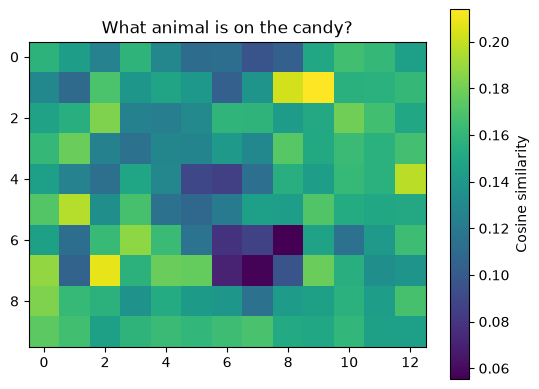

In [47]:
import matplotlib.pyplot as plt
_, h, w = inputs["image_grid_thw"][0].tolist()

plt.imshow(scores.reshape(h, w).detach().cpu(),cmap="viridis")
plt.colorbar(label="Cosine similarity")
plt.title(question)
plt.show()

In [48]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_relevance(image, question, scores, image_grid_thw):
    _, h, w = image_grid_thw[0].tolist()

    heatmap = scores.detach().float().cpu().reshape(h, w).numpy()

    # Match the processed image grid
    img = image.resize((w * 40, h * 40))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].imshow(img)
    axes[0].set_title("Original image")

    axes[1].imshow(heatmap, cmap="jet", interpolation="nearest")
    axes[1].set_title(f"Cosine similarity ({h} × {w})")

    axes[2].imshow(img)
    overlay = axes[2].imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
        interpolation="nearest",
        extent=(0, img.width, img.height, 0)
    )
    axes[2].set_title("Question relevance overlay")

    for ax in axes:
        ax.axis("off")

    fig.colorbar(overlay, ax=axes, shrink=0.7,
                 label="Cosine similarity")

    fig.suptitle(question, fontsize=14)
    plt.show()

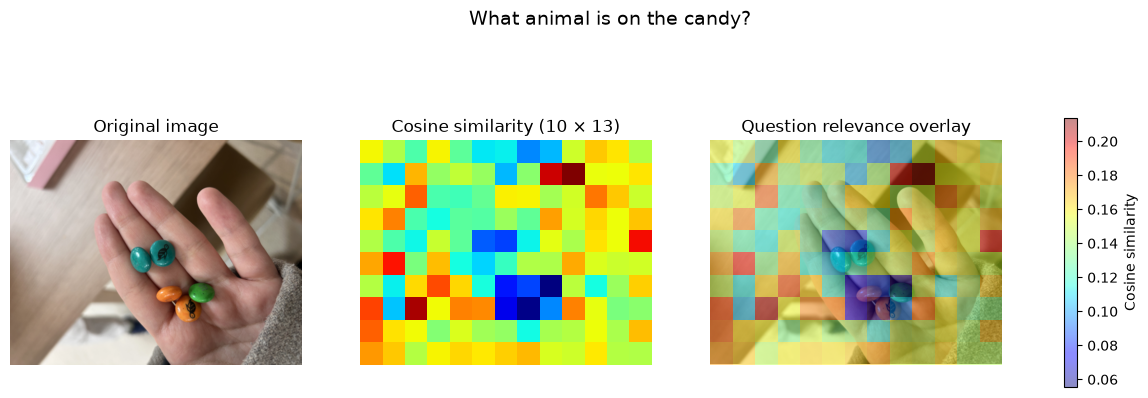

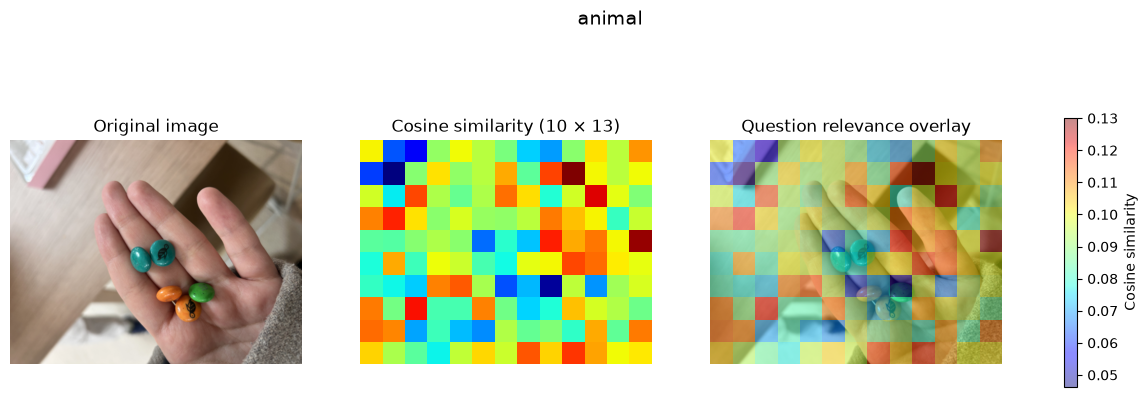

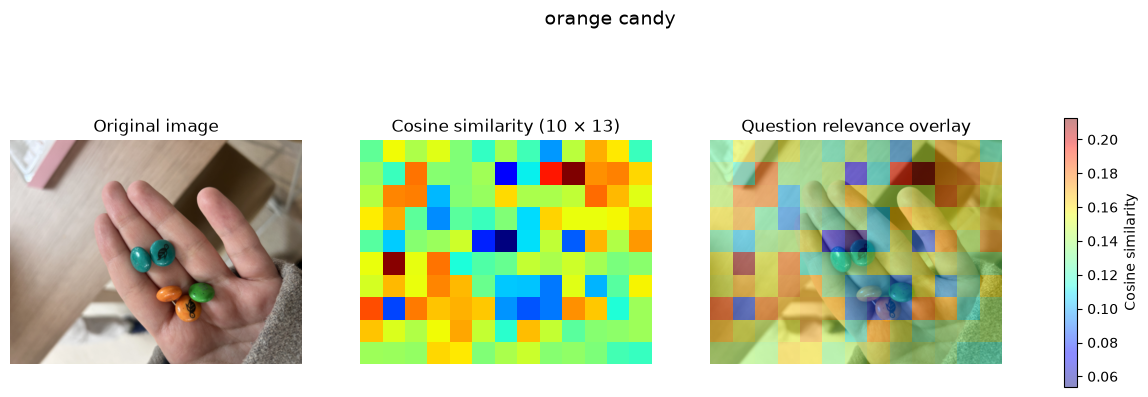

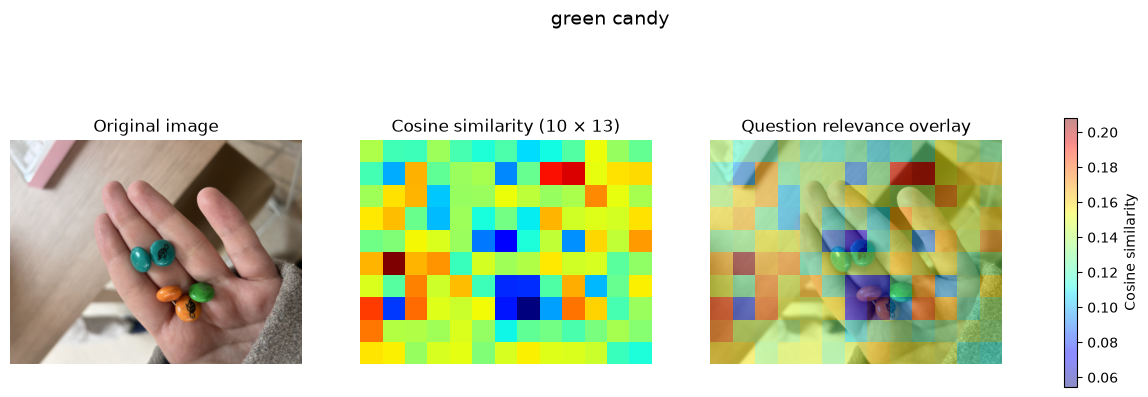

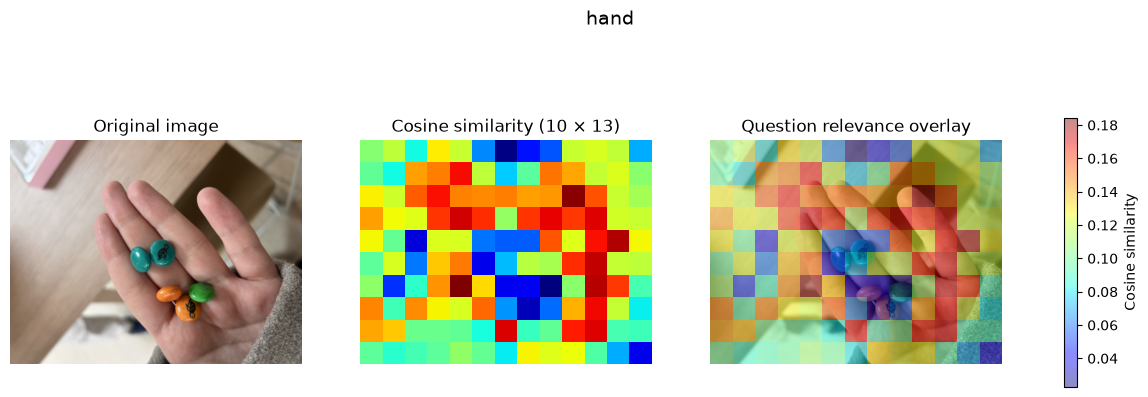

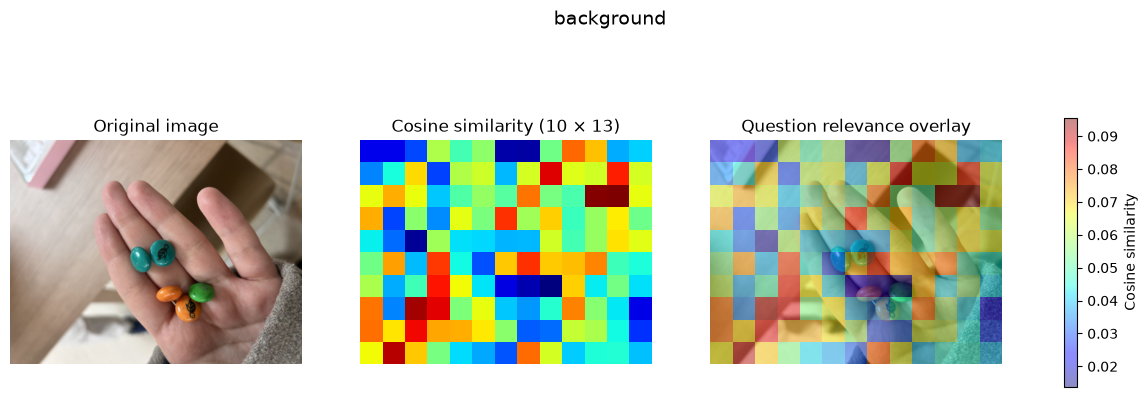

In [49]:
questions = [
    "What animal is on the candy?",
    "animal",
    "orange candy",
    "green candy",
    "hand",
    "background"
]

for q in questions:
    text_emb = get_question_embeddings(q)

    _, scores = text_guided_selector(
        visual_tokens, text_emb, k=0.5
    )

    visualize_relevance(
        image, q, scores, inputs["image_grid_thw"]
    )

In [50]:
attention = language_model.layers[0].self_attn

print(inspect.getsource(type(attention).forward))
print("Attention backend:",
      language_model.config._attn_implementation)

    @deprecate_kwarg("past_key_values", "5.40.0", new_name="cache")
    def forward(
        self,
        hidden_states: torch.Tensor,
        attention_mask: torch.Tensor | None,
        relative_distance: torch.Tensor,
        conv_mask: torch.Tensor | None = None,
        cache: Cache | None = None,
        key_hidden_states: torch.Tensor | None = None,
        value_hidden_states: torch.Tensor | None = None,
        cache_offset: int = 0,
        **kwargs: Unpack[TransformersKwargs],
    ) -> tuple[torch.Tensor, torch.Tensor | None]:
        r"""
        relative_distance (`torch.Tensor` of shape `(query_length, key_length)`):
            Distance from each query position to each key position, see `get_relative_distance`.
        key_hidden_states (`torch.Tensor`, *optional*):
            Input of the key projection, `hidden_states` by default.
        value_hidden_states (`torch.Tensor`, *optional*):
            Input of the value projection, `hidden_states` by default.
        c

In [51]:
set_loops(1)

with torch.inference_mode():
    outputs = model(
        **inputs,
        output_attentions=True,
        use_cache=False,
        logits_to_keep=1
    )

attentions = outputs.attentions

if attentions is None:
    print("Attention weights unavailable")
else:
    for i, attn in enumerate(attentions):
        print(i, attn.shape if attn is not None else None)

0 torch.Size([1, 24, 154, 154])
1 torch.Size([1, 24, 154, 154])
2 torch.Size([1, 24, 154, 154])
3 torch.Size([1, 24, 154, 154])
4 torch.Size([1, 24, 154, 154])
5 torch.Size([1, 24, 154, 154])
6 torch.Size([1, 24, 154, 154])
7 torch.Size([1, 24, 154, 154])
8 torch.Size([1, 24, 154, 154])
9 torch.Size([1, 24, 154, 154])
10 torch.Size([1, 24, 154, 154])
11 torch.Size([1, 24, 154, 154])
12 torch.Size([1, 24, 154, 154])
13 torch.Size([1, 24, 154, 154])
14 torch.Size([1, 24, 154, 154])
15 torch.Size([1, 24, 154, 154])
16 torch.Size([1, 24, 154, 154])
17 torch.Size([1, 24, 154, 154])
18 torch.Size([1, 24, 154, 154])
19 torch.Size([1, 24, 154, 154])
20 torch.Size([1, 24, 154, 154])
21 torch.Size([1, 24, 154, 154])
22 torch.Size([1, 24, 154, 154])
23 torch.Size([1, 24, 154, 154])


#### Decoder based pruning

In [52]:
image_positions = (
    inputs["input_ids"][0] == model.config.image_token_id
).nonzero(as_tuple=True)[0]

ids = inputs["input_ids"][0].tolist()

q_ids = processor.tokenizer(
    question, add_special_tokens=False
)["input_ids"]

matches = [
    i for i in range(len(ids) - len(q_ids) + 1)
    if ids[i:i + len(q_ids)] == q_ids
    and i > image_positions[-1].item()
]

assert matches, "Question token sequence not found"

start = matches[-1]
question_positions = torch.arange(start, start + len(q_ids))

print("Image tokens:", len(image_positions))
print("Question tokens:", len(question_positions))
print("Question:", processor.decode(ids[start:start + len(q_ids)]))

Image tokens: 130
Question tokens: 8
Question: What animal is on the candy?


In [53]:
def attention_relevance(attention, question_positions, image_positions):
    A = attention[0].float()

    A = A.index_select(1, question_positions.to(A.device))
    A = A.index_select(2, image_positions.to(A.device))

    # Average across attention heads and question tokens
    scores = A.mean(dim=(0, 1))

    return scores

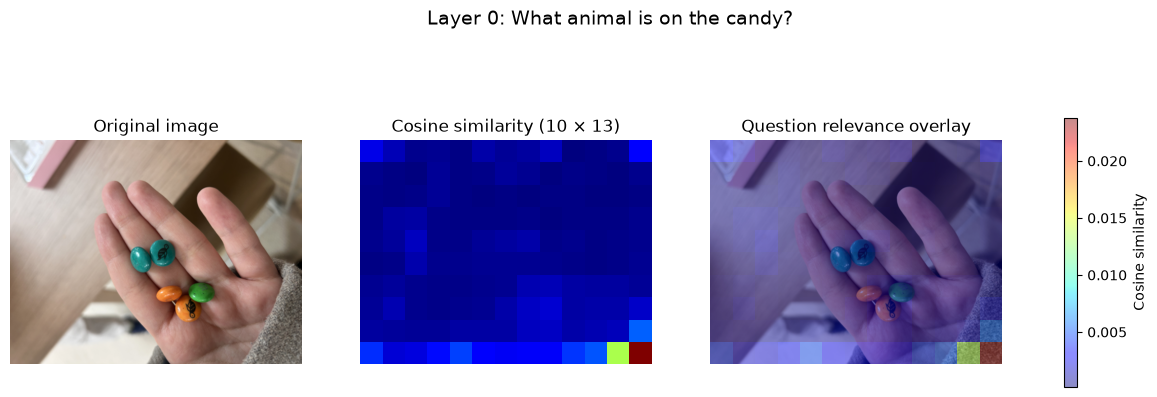

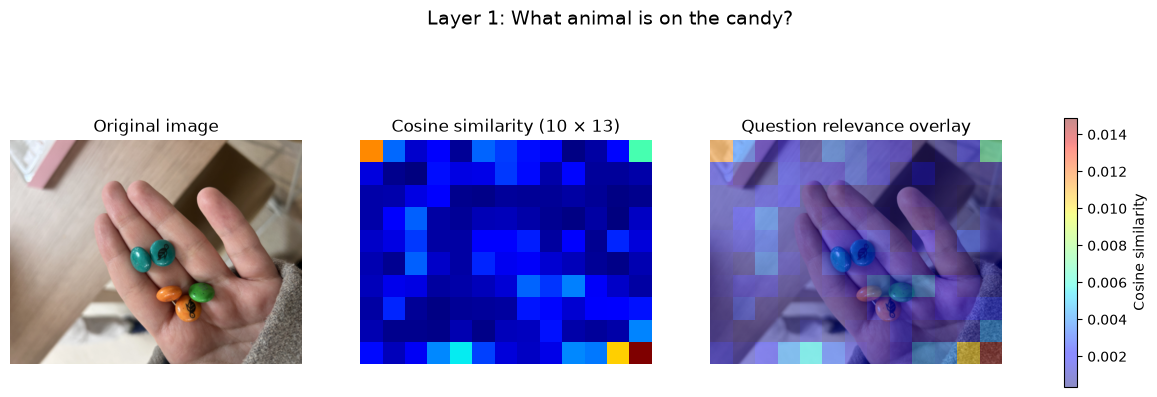

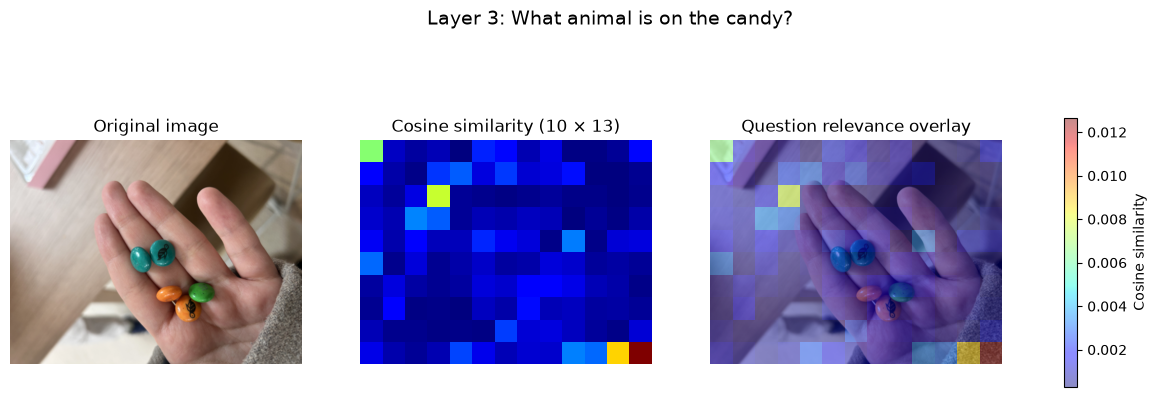

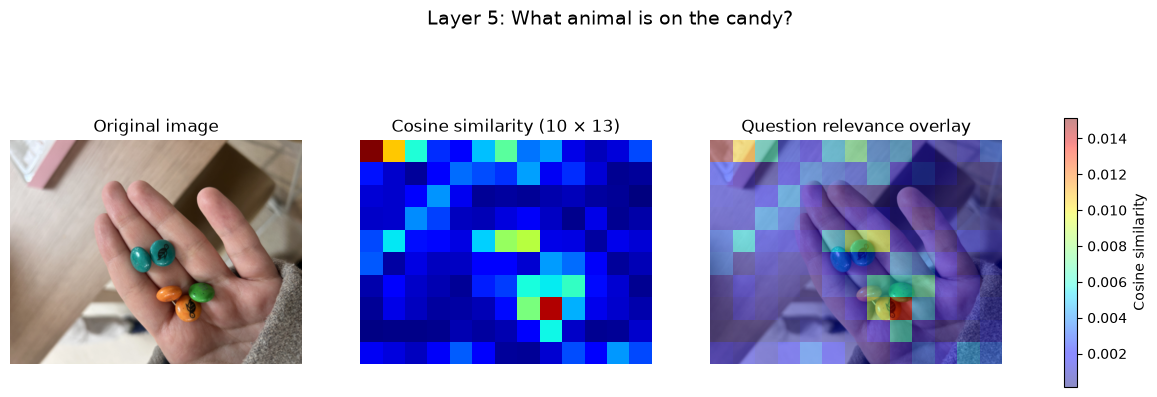

In [56]:
for layer in [0, 1, 3, 5]:
    scores = attention_relevance(
        attentions[layer],
        question_positions,
        image_positions
    )

    visualize_relevance(
        image,
        f"Layer {layer}: {question}",
        scores,
        inputs["image_grid_thw"]
    )

In [58]:

set_loops(3)
def attention_selector(scores, k=0.5):
    assert 0 < k <= 1

    n_keep = max(1, int(len(scores) * k))

    indices = scores.topk(n_keep).indices
    return indices.sort().values

for layer in range(6):
    scores = attention_relevance(
        attentions[layer],
        question_positions,
        image_positions
    )

    indices = attention_selector(scores, k=0.5)
    pruned = prune_inputs(inputs, vision_outputs, indices)

    tokens = generate_tokens(pruned)

    print(f"\nLayer: {layer}")
    print(processor.decode(tokens, skip_special_tokens=True))



Layer: 0
We need answer image question. Need inspect image. It shows hand with candy-like round candies. Some have black design. The orange candy in front has black symbol that looks like a treble clef? Wait user asks what animal is on the candy. Need identify animal. Let's zoom mentally: candies are round, maybe jelly beans? The teal candies have black logo resembling maybe a snail? Orange candy has black design that looks like a treble clef? Green candy plain. The black marking on teal and orange appears like a stylized animal? Could be a snail? Let's analyze visual details.

Image: four round candies. Two turquoise/teal, one orange, one green. On teal candies: black design looks like a small shape with a curved body and maybe antennae? On orange: black design clearly looks like a treble clef? Actually could be a snail silhouette: round body with spiral shell and eyestalks. A snail icon often has a spiral shell and a body with antennae. In the image, black marking on orange looks li